In [2]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import smarts_cerebellum.globals as gl

lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', 'patients_MNISymC_FaMap_MCP_lme.tsv'), sep = '\t')
lme['Week'] = lme['Week'].astype(int)
lme = lme.sort_values('Week')

obs = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_MCP_FaMap.tsv'), sep = '\t')
obs = obs[obs.regionname == 'MCP_L']

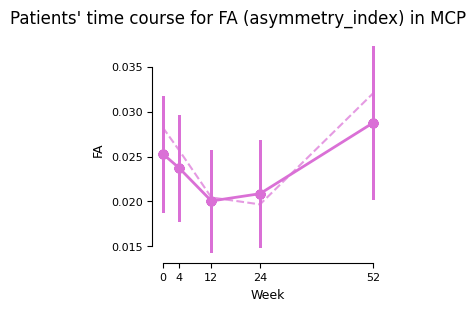

In [2]:
fig, ax = plt.subplots(figsize=(3,3), sharey = True, constrained_layout=True)

lme_ai = lme[(lme.regionname == 'MCP_ai')].sort_values('Week')

obs_ai = obs[obs.regionname == 'MCP_L'].groupby('Week')['asymmetry_index'].mean().reset_index()

ax.errorbar(x = lme_ai['Week'], y = lme_ai['beta'], yerr = lme_ai['se'], fmt = '-o', linewidth = 2, color = 'orchid')
ax.plot(obs_ai['Week'], obs_ai['asymmetry_index'], alpha = .7, linestyle = '--', color = 'orchid')


ax.set_xticks(gl.weeks)
ax.set_ylabel("FA")
ax.set_xlabel("Week")

plt.suptitle(f"Patients' time course for FA (asymmetry_index) in MCP")
sns.despine(trim = True)
plt.show()

In [14]:
obs.head(12)

,image,image_name,frame,region,regionname,volume,atlas,median,mean,Week,...,isPatient,LesionSide,LesionLocation,handedness,hemisphere,region_bilat,side,ratio,log_ratio,asymmetry_index
0,1,CU_2310_W0_MNISymC_FaMap_FlipLR.nii.gz,0,3,MCP_L,7777.0,MNISymC.MCP_no_ventral_pons.nii,0.413985,0.432976,0,...,1,left,subcortical,2,L,MCP_,contralesional,0.938740,-0.063217,0.031598
1,1,CU_2310_W0_MNISymC_FaMap_FlipLR.nii.gz,0,4,MCP_R,8201.0,MNISymC.MCP_no_ventral_pons.nii,0.384455,0.406452,0,...,1,left,subcortical,2,R,MCP_,ipsilesional,0.938740,-0.063217,0.031598
2,2,CU_2310_W4_MNISymC_FaMap_FlipLR.nii.gz,0,3,MCP_L,7777.0,MNISymC.MCP_no_ventral_pons.nii,0.414204,0.432727,4,...,1,left,subcortical,2,L,MCP_,contralesional,0.944687,-0.056901,0.028443
3,2,CU_2310_W4_MNISymC_FaMap_FlipLR.nii.gz,0,4,MCP_R,8201.0,MNISymC.MCP_no_ventral_pons.nii,0.388952,0.408792,4,...,1,left,subcortical,2,R,MCP_,ipsilesional,0.944687,-0.056901,0.028443
4,3,CU_2310_W12_MNISymC_FaMap_FlipLR.nii.gz,0,3,MCP_L,7777.0,MNISymC.MCP_no_ventral_pons.nii,0.387789,0.400333,12,...,1,left,subcortical,2,L,MCP_,contralesional,0.901154,-0.104079,0.051993
5,3,CU_2310_W12_MNISymC_FaMap_FlipLR.nii.gz,0,4,MCP_R,8201.0,MNISymC.MCP_no_ventral_pons.nii,0.325018,0.360762,12,...,1,left,subcortical,2,R,MCP_,ipsilesional,0.901154,-0.104079,0.051993
6,4,CU_2310_W24_MNISymC_FaMap_FlipLR.nii.gz,0,3,MCP_L,7777.0,MNISymC.MCP_no_ventral_pons.nii,0.392171,0.409757,24,...,1,left,subcortical,2,L,MCP_,contralesional,0.967060,-0.033495,0.016746
7,4,CU_2310_W24_MNISymC_FaMap_FlipLR.nii.gz,0,4,MCP_R,8201.0,MNISymC.MCP_no_ventral_pons.nii,0.366687,0.396259,24,...,1,left,subcortical,2,R,MCP_,ipsilesional,0.967060,-0.033495,0.016746
8,5,CU_2310_W52_MNISymC_FaMap_FlipLR.nii.gz,0,3,MCP_L,7777.0,MNISymC.MCP_no_ventral_pons.nii,0.403197,0.420693,52,...,1,left,subcortical,2,L,MCP_,contralesional,0.944478,-0.057123,0.028554
9,5,CU_2310_W52_MNISymC_FaMap_FlipLR.nii.gz,0,4,MCP_R,8201.0,MNISymC.MCP_no_ventral_pons.nii,0.359092,0.397335,52,...,1,left,subcortical,2,R,MCP_,ipsilesional,0.944478,-0.057123,0.028554


<Axes: xlabel='Week', ylabel='asymmetry_index'>

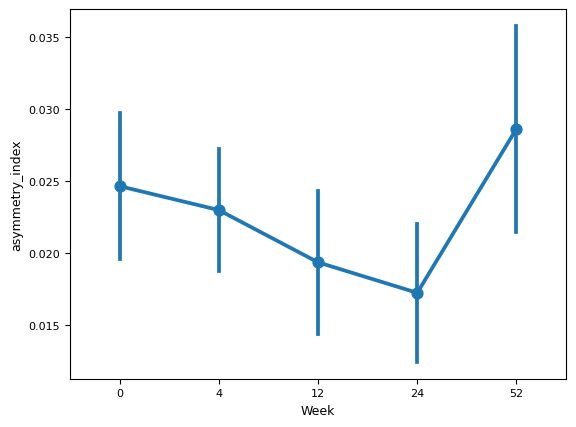

In [11]:
obs = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_MCP_FaMap.tsv'), sep = '\t')

obs

sns.pointplot(x = 'Week', y = 'asymmetry_index', data = obs[obs.regionname == 'MCP_L'], errorbar = 'se')
#sns.pointplot(x = 'Week', y = 'mean', data = obs[obs.regionname == 'MCP_R'], errorbar = 'se')


In [3]:
print(f'---t-test against 0 for asymmetry index of FA in MCP (patients)--- \n')
for week in obs.Week.unique():
    t_val, p_val = stats.ttest_1samp(obs[obs.Week == week]['asymmetry_index'], popmean = 0)
    print(f'Week {week}: t-value = {t_val}, p-value = {p_val} \n')
    

---t-test against 0 for asymmetry index of FA in MCP (patients)--- 

Week 0: t-value = 4.250385673462092, p-value = 0.0013648548786992962 

Week 4: t-value = 4.743375355045329, p-value = 0.00026140405876713506 

Week 12: t-value = 3.325021471918795, p-value = 0.00428720135699656 

Week 24: t-value = 2.9196052185154397, p-value = 0.011199496592434044 

Week 52: t-value = 2.823411686097529, p-value = 0.03695995590433593 

